[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/fingerprint-similarity-guide/blob/main/notebooks/04_benchmark_virtual_screening.ipynb)

# 04 · Benchmark 1 — Virtual Screening Recovery

*Fingerprint & Similarity Guide · Hamza Hentabli, Ph.D. · ~50 min*

Time for real numbers. The first and most common use of fingerprint similarity is **ligand-based virtual screening**: given one or more known actives, rank a library so the other actives float to the top. We run this on the **DUD-E EGFR** set (542 actives + property-matched decoys) for every fingerprint × metric and report enrichment factor, BEDROC and ROC-AUC. Every number here is computed in this notebook, not quoted.

**Learning objectives.** By the end of this notebook you will be able to:

- run a ligand-based virtual screen and rank a mixed active/decoy library
- compute **EF1% / EF5%**, **BEDROC** and **ROC-AUC** with RDKit's scoring functions
- compare all fingerprints (Tanimoto) and read the full fingerprint × metric grid
- state which fingerprint + metric actually wins virtual screening on this set

In [1]:
# Setup: on Google Colab this installs dependencies and clones the repo so the
# cached data and the shared `fsg` helper module are available. Running locally,
# install requirements.txt once and this cell just locates the files.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
OFFLINE = os.environ.get("FSG_OFFLINE", "0") == "1"   # CI sets this; no notebook needs the network
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "rdkit", "scikit-learn", "scipy", "pandas", "matplotlib"], check=True)
    if not os.path.isdir("fingerprint-similarity-guide"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/fingerprint-similarity-guide.git"], check=True)
    ROOT = "fingerprint-similarity-guide"
else:
    ROOT = ".." if os.path.isdir("../data") else "."
DATA_DIR = os.path.join(ROOT, "data")
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
import fsg   # shared fingerprint factory + metrics + evaluation

print("Colab:", IN_COLAB, "| offline:", OFFLINE, "| data:", DATA_DIR)
print("Fingerprints available:", ", ".join(fsg.FP_NAMES))

Colab: False | offline: True | data: ../data
Fingerprints available: ECFP4-1024, ECFP4-2048, ECFP6-2048, ECFP4-counts, FCFP4-2048, RDKit, AtomPair, Torsion, MACCS, Avalon


In [2]:
import numpy as np, pandas as pd
act = fsg.load_mols(pd.read_csv(f"{DATA_DIR}/dude_egfr_actives.csv"))
dec = fsg.load_mols(pd.read_csv(f"{DATA_DIR}/dude_egfr_decoys.csv"))
print(f"DUD-E EGFR benchmark: {len(act)} actives, {len(dec)} property-matched decoys")
# the exact query set used by scripts/run_benchmarks.py (so live numbers match the JSON)
query_idx = sorted(np.random.default_rng(7).choice(len(act), size=25, replace=False).tolist())
print("query actives (seed 7):", len(query_idx))

DUD-E EGFR benchmark: 542 actives, 3000 property-matched decoys
query actives (seed 7): 25


## 1. The protocol

For each **query** active we rank the rest of the library (other actives + all decoys) by similarity to it, then score how early the other actives appear. We average over 25 query actives so the result does not depend on one lucky seed. A *single* query (rather than max-over-all-542-analogues) avoids DUD-E's well-known analogue-bias saturation, so the fingerprints are actually separated.

**Metrics.** EF1% = how many times more actives than random in the top 1%; BEDROC (α=20) weights the very top of the list; ROC-AUC is the overall ranking quality.

## 2. All fingerprints, Tanimoto — computed live

This recomputes the screen here using the shared `fsg.ligand_based_screen` (the exact code `scripts/run_benchmarks.py` uses), so these numbers match the committed results.

In [3]:
act_fps = {n: fsg.make_fps(n, list(act["mol"])) for n in fsg.FP_NAMES}
dec_fps = {n: fsg.make_fps(n, list(dec["mol"])) for n in fsg.FP_NAMES}

rows = []
for name in fsg.FP_NAMES:
    m = fsg.ligand_based_screen(act_fps[name], dec_fps[name], "tanimoto", query_idx)
    rows.append((name, m["EF1%"], m["EF5%"], m["BEDROC"], m["AUC"]))
vs_tani = pd.DataFrame(rows, columns=["fingerprint", "EF1%", "EF5%", "BEDROC", "AUC"]).sort_values("BEDROC", ascending=False)
vs_tani.reset_index(drop=True)

,fingerprint,EF1%,EF5%,BEDROC,AUC
0,Torsion,6.185,5.893,0.851,0.902
1,ECFP4-2048,6.208,5.922,0.849,0.876
2,ECFP6-2048,6.222,5.858,0.832,0.862
3,ECFP4-counts,6.170,5.820,0.830,0.874
4,ECFP4-1024,6.200,5.864,0.829,0.863
5,FCFP4-2048,6.164,5.784,0.821,0.859
6,Avalon,5.566,5.110,0.698,0.792
7,AtomPair,6.010,5.061,0.680,0.754
8,RDKit,5.341,4.139,0.587,0.714
9,MACCS,5.178,3.862,0.532,0.668


With **Tanimoto**, the circular (ECFP/FCFP) and torsion fingerprints lead; MACCS and RDKit paths trail. A 166-bit key set simply cannot rank a focused library as sharply as a 2,048-bit environment fingerprint.

## 3. Recovery curves

The clearest picture is the recovery curve: what fraction of actives you have found after screening the top x% of the ranked library. Higher and earlier is better.

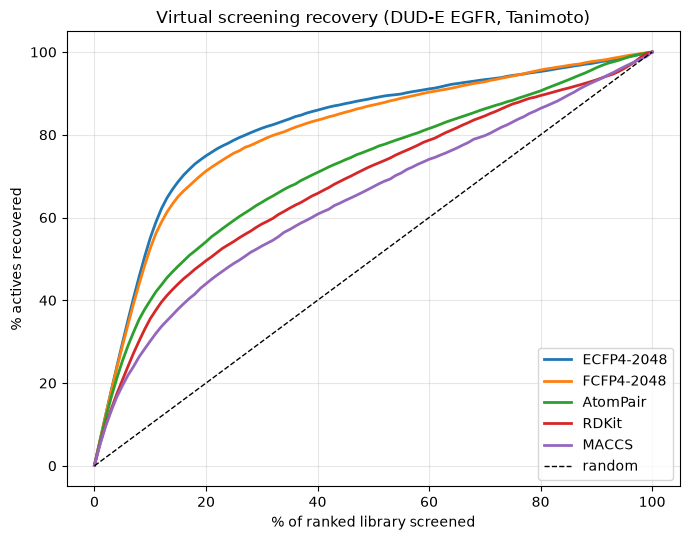

In [4]:
import matplotlib.pyplot as plt
grid = np.linspace(0, 1, 101)
plt.figure(figsize=(7, 5.5))
for name in ["ECFP4-2048", "FCFP4-2048", "AtomPair", "RDKit", "MACCS"]:
    afps, dfps = act_fps[name], dec_fps[name]
    curves = []
    for q in query_idx:
        cand = [afps[i] for i in range(len(afps)) if i != q]
        s = np.array(list(fsg.bulk_similarity("tanimoto", afps[q], cand)) +
                     list(fsg.bulk_similarity("tanimoto", afps[q], dfps)))
        y = np.array([1]*len(cand) + [0]*len(dfps))[np.argsort(-s, kind="mergesort")]
        recall = np.cumsum(y) / y.sum()
        curves.append(np.interp(grid, np.arange(1, len(y)+1)/len(y), recall))
    plt.plot(grid*100, np.mean(curves, 0)*100, lw=2, label=name)
plt.plot([0,100],[0,100],"k--",lw=1,label="random")
plt.xlabel("% of ranked library screened"); plt.ylabel("% actives recovered")
plt.title("Virtual screening recovery (DUD-E EGFR, Tanimoto)")
plt.legend(loc="lower right"); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 4. The full fingerprint × metric grid

Metric choice matters too. The committed results (`docs/benchmark_results.json`, produced by `scripts/run_benchmarks.py` over all 10 fingerprints × 5 metrics) give the complete picture. Here is BEDROC for every combination.

In [5]:
import json, os
import pandas as pd
DOCS_DIR = os.path.join(ROOT, "docs")
RESULTS = json.load(open(os.path.join(DOCS_DIR, "benchmark_results.json")))
print("Loaded committed benchmark results from docs/benchmark_results.json")

Loaded committed benchmark results from docs/benchmark_results.json


In [6]:
b1 = RESULTS["benchmark1_virtual_screening"]["scores"]
metrics = ["tanimoto", "dice", "cosine", "tversky", "russel"]
grid_df = pd.DataFrame(index=fsg.FP_NAMES, columns=metrics, dtype=float)
for key, v in b1.items():
    fp, mt = key.split("|"); grid_df.loc[fp, mt] = v["BEDROC"]
grid_df.round(3)

,tanimoto,dice,cosine,tversky,russel
ECFP4-1024,0.829,0.829,0.832,0.831,0.847
ECFP4-2048,0.849,0.849,0.851,0.848,0.862
ECFP6-2048,0.832,0.832,0.834,0.834,0.848
ECFP4-counts,0.830,0.830,NaN,NaN,NaN
FCFP4-2048,0.821,0.821,0.821,0.843,0.861
RDKit,0.587,0.587,0.546,0.316,0.246
AtomPair,0.680,0.680,0.702,0.665,0.659
Torsion,0.851,0.851,0.852,0.833,0.841
MACCS,0.532,0.532,0.534,0.414,0.409
Avalon,0.698,0.698,0.709,0.556,0.462


Reading the grid: the **best virtual-screening combinations on this set** are circular/torsion fingerprints, and for those, Tanimoto/Dice/Cosine are near-interchangeable while Tversky and Russel-Rao can help ECFP slightly. For **RDKit** paths, however, Tversky and Russel-Rao are *actively harmful* — a reminder that the right metric depends on the fingerprint.

In [7]:
best = max(b1.items(), key=lambda kv: kv[1]["BEDROC"])
print("Best VS combination on DUD-E EGFR (BEDROC):", best[0], "->", best[1])

Best VS combination on DUD-E EGFR (BEDROC): ECFP4-2048|russel -> {'EF1%': 6.302, 'EF5%': 6.061, 'BEDROC': 0.862, 'AUC': 0.871}


## Summary

- On DUD-E EGFR, **circular (ECFP/FCFP) and torsion fingerprints win** virtual screening; MACCS and RDKit-path trail by a wide margin.
- Among metrics, Tanimoto/Dice/Cosine are close for good fingerprints; **Russel-Rao/Tversky can help ECFP but wreck RDKit** — metric choice is fingerprint-dependent.
- EF1% near its ceiling means you recover most actives in the first 1% screened.

Next: a harder question — can these fingerprints find actives built on a *different scaffold*?

### ✏️ Exercise 1

Rank the fingerprints by EF1% (Tanimoto) instead of BEDROC. Does the top fingerprint change?

<details>
<summary><b>Show solution</b></summary>

```python
print(vs_tani.sort_values("EF1%", ascending=False)[["fingerprint","EF1%","BEDROC"]].head())
```

</details>

### ✏️ Exercise 2

For the RDKit fingerprint, compare BEDROC under Tanimoto vs Russel-Rao from the grid. By how much does the wrong metric hurt it?

<details>
<summary><b>Show solution</b></summary>

```python
print("RDKit Tanimoto:", grid_df.loc["RDKit","tanimoto"], "| Russel:", grid_df.loc["RDKit","russel"])
```

</details>